In [1]:
# 1. Imports & Setup
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array
from tensorflow.keras.utils import plot_model

# Reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
# 2. Dataset Paths (exactly as you provided)
BASE = "/kaggle/input/datasets"

# Dataset 1 – Deepfake Image Detection
DF_TRAIN = f"{BASE}/saurabhbagchi/deepfake-image-detection/train-20250112T065955Z-001/train"
DF_TEST  = f"{BASE}/saurabhbagchi/deepfake-image-detection/test-20250112T065939Z-001/test"
DF_SAMPLE_FAKE = f"{BASE}/saurabhbagchi/deepfake-image-detection/Sample_fake_images/Sample_fake_images/fake"

# Dataset 2 – CIFAKE
CIFAKE_TRAIN = f"{BASE}/birdy654/cifake-real-and-ai-generated-synthetic-images/train"
CIFAKE_TEST  = f"{BASE}/birdy654/cifake-real-and-ai-generated-synthetic-images/test"

print("Paths set.")

Paths set.


In [3]:
# 3. Configuration
IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
EPOCHS     = 15
LR         = 1e-4

In [4]:
# -----------------------------------------------------------
# 4. Data Generators (FIXED for EfficientNet)
# -----------------------------------------------------------
from tensorflow.keras.applications.efficientnet import preprocess_input

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,   # ← this is the key fix
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest',
    validation_split=0.15
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input    # ← also for test
)

# ---- Training + Validation from CIFAKE ----
train_gen = train_datagen.flow_from_directory(
    CIFAKE_TRAIN,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='training',
    seed=SEED,
    shuffle=True
)

val_gen = train_datagen.flow_from_directory(
    CIFAKE_TRAIN,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    subset='validation',
    seed=SEED,
    shuffle=False
)

# ---- Test set from CIFAKE ----
test_gen = test_datagen.flow_from_directory(
    CIFAKE_TEST,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

# Optional Deepfake test set
df_test_gen = test_datagen.flow_from_directory(
    DF_TEST,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

print("Class indices:", train_gen.class_indices)

Found 85000 images belonging to 2 classes.
Found 15000 images belonging to 2 classes.
Found 20000 images belonging to 2 classes.
Found 499 images belonging to 2 classes.
Class indices: {'FAKE': 0, 'REAL': 1}


In [5]:
print("CIFAKE class mapping:", train_gen.class_indices)

CIFAKE class mapping: {'FAKE': 0, 'REAL': 1}


In [6]:
# 5. Build Model – EfficientNetB0 (Transfer Learning)
def build_model(input_shape=(224, 224, 3)):
    base = EfficientNetB0(
        include_top=False,
        weights='imagenet',
        input_shape=input_shape,
        pooling='avg'
    )
    base.trainable = False          # freeze first

    inputs = layers.Input(shape=input_shape)
    x = base(inputs, training=False)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)   # binary: fake probability

    model = models.Model(inputs, outputs)
    return model

model = build_model()
model.summary()

I0000 00:00:1792269488.174461      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792269488.178417      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 1280)           │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,377,764 (16.70 MB)

 Trainable params: 328,193 (1.25 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [7]:
# 6. Compile
model.compile(
    optimizer=optimizers.Adam(learning_rate=LR),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

In [8]:
# 7. Callbacks – save the BEST model
os.makedirs('/kaggle/working/models', exist_ok=True)

checkpoint = callbacks.ModelCheckpoint(
    filepath='/kaggle/working/models/best_deepfake_detector.keras',
    monitor='val_auc',
    mode='max',
    save_best_only=True,
    verbose=1
)

early_stop = callbacks.EarlyStopping(
    monitor='val_auc',
    patience=4,
    restore_best_weights=True,
    mode='max',
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# 8. Train
# ------------------------------------------------------------
history = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    callbacks=[checkpoint, early_stop, reduce_lr],
    verbose=1
)

Epoch 1/15


2026-10-17 20:38:32.966947: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 20:38:33.110007: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 20:38:33.451878: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 20:38:33.593640: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 20:38:34.395718: E external/local_xla/xla/stream_

1695/2657 ━━━━━━━━━━━━━━━━━━━━ 6:55 432ms/step - accuracy: 0.7748 - auc: 0.8527 - loss: 0.4697

2026-10-17 20:51:00.567025: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 20:51:00.703406: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 20:51:01.024692: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 20:51:01.165824: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 20:51:01.945767: E external/local_xla/xla/stream_

2657/2657 ━━━━━━━━━━━━━━━━━━━━ 0s 444ms/step - accuracy: 0.7917 - auc: 0.8705 - loss: 0.4440

2026-10-17 21:01:59.974181: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 21:02:00.118372: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 21:02:00.463183: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 21:02:00.604741: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-17 21:02:01.378075: E external/local_xla/xla/stream_


Epoch 1: val_auc improved from None to 0.95576, saving model to /kaggle/working/models/best_deepfake_detector.keras

Epoch 1: finished saving model to /kaggle/working/models/best_deepfake_detector.keras
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1433s 529ms/step - accuracy: 0.8263 - auc: 0.9063 - loss: 0.3896 - val_accuracy: 0.8855 - val_auc: 0.9558 - val_loss: 0.2842 - learning_rate: 1.0000e-04
Epoch 2/15
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 0s 372ms/step - accuracy: 0.8542 - auc: 0.9299 - loss: 0.3379
Epoch 2: val_auc improved from 0.95576 to 0.96281, saving model to /kaggle/working/models/best_deepfake_detector.keras

Epoch 2: finished saving model to /kaggle/working/models/best_deepfake_detector.keras
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1163s 438ms/step - accuracy: 0.8570 - auc: 0.9323 - loss: 0.3323 - val_accuracy: 0.8964 - val_auc: 0.9628 - val_loss: 0.2558 - learning_rate: 1.0000e-04
Epoch 3/15
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step - accuracy: 0.8612 - auc: 0.9354 - loss: 0.3245
Epoch 3: val_a

In [9]:
# 9. Optional Fine-tuning (unfreeze top layers)
print("\n>>> Starting fine-tuning...")
base_model = model.layers[1]          # EfficientNetB0
base_model.trainable = True

# Freeze early layers, train only the last ~30%
for layer in base_model.layers[:-30]:
    layer.trainable = False

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),   # lower LR
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

history_ft = model.fit(
    train_gen,
    epochs=8,
    validation_data=val_gen,
    callbacks=[checkpoint, early_stop, reduce_lr],
    verbose=1
)


>>> Starting fine-tuning...
Epoch 1/8
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 0s 358ms/step - accuracy: 0.8273 - auc: 0.9058 - loss: 0.4508
Epoch 1: val_auc did not improve from 0.97999
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1152s 424ms/step - accuracy: 0.8499 - auc: 0.9264 - loss: 0.3777 - val_accuracy: 0.9195 - val_auc: 0.9751 - val_loss: 0.2017 - learning_rate: 1.0000e-05
Epoch 2/8
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 0s 350ms/step - accuracy: 0.8857 - auc: 0.9532 - loss: 0.2826
Epoch 2: val_auc improved from 0.97999 to 0.98125, saving model to /kaggle/working/models/best_deepfake_detector.keras

Epoch 2: finished saving model to /kaggle/working/models/best_deepfake_detector.keras
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 1095s 412ms/step - accuracy: 0.8897 - auc: 0.9559 - loss: 0.2730 - val_accuracy: 0.9307 - val_auc: 0.9813 - val_loss: 0.1743 - learning_rate: 1.0000e-05
Epoch 3/8
2657/2657 ━━━━━━━━━━━━━━━━━━━━ 0s 368ms/step - accuracy: 0.8973 - auc: 0.9619 - loss: 0.2515
Epoch 3: val_auc improved from 0.98125 to 

In [10]:
# 10. Load the best model
best_model = tf.keras.models.load_model('/kaggle/working/models/best_deepfake_detector.keras')
print("Best model loaded.")

Best model loaded.


In [11]:
# 11. Evaluation on CIFAKE Test set
print("\n=== Evaluation on CIFAKE Test Set ===")
test_loss, test_acc, test_auc = best_model.evaluate(test_gen, verbose=1)
print(f"Test Accuracy : {test_acc:.4f}")
print(f"Test AUC      : {test_auc:.4f}")

# Predictions for detailed metrics
y_true = test_gen.classes
y_prob = best_model.predict(test_gen).ravel()
y_pred = (y_prob > 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['FAKE', 'REAL']))


=== Evaluation on CIFAKE Test Set ===
625/625 ━━━━━━━━━━━━━━━━━━━━ 150s 227ms/step - accuracy: 0.8863 - auc: 0.9765 - loss: 0.2803
Test Accuracy : 0.8863
Test AUC      : 0.9765
625/625 ━━━━━━━━━━━━━━━━━━━━ 35s 46ms/step

Classification Report:
              precision    recall  f1-score   support

        FAKE       0.98      0.79      0.87     10000
        REAL       0.82      0.98      0.90     10000

    accuracy                           0.89     20000
   macro avg       0.90      0.89      0.89     20000
weighted avg       0.90      0.89      0.89     20000



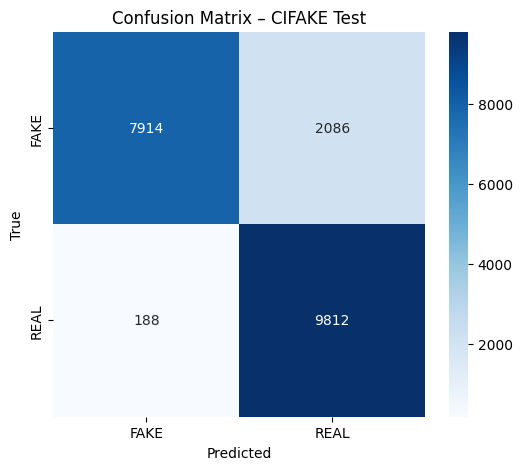

In [12]:
# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['FAKE', 'REAL'], yticklabels=['FAKE', 'REAL'])
plt.title('Confusion Matrix – CIFAKE Test')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.show()

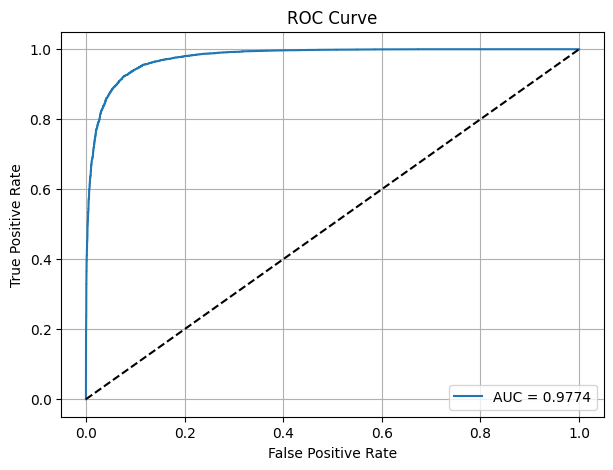

In [13]:
# ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_true, y_prob):.4f}')
plt.plot([0,1], [0,1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

In [14]:
# 12. Extra evaluation on the Deepfake dataset (optional)
print("\n=== Evaluation on Deepfake Image Detection Test Set ===")
df_loss, df_acc, df_auc = best_model.evaluate(df_test_gen, verbose=1)
print(f"Deepfake Test Accuracy : {df_acc:.4f}")
print(f"Deepfake Test AUC      : {df_auc:.4f}")



=== Evaluation on Deepfake Image Detection Test Set ===


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


15/16 ━━━━━━━━━━━━━━━━━━━━ 0s 978ms/step - accuracy: 0.5688 - auc: 0.1053 - loss: 1.0928

2026-10-18 04:09:01.697898: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 04:09:01.838231: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 04:09:02.167054: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 04:09:02.308431: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 04:09:03.094042: E external/local_xla/xla/stream_

16/16 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.5571 - auc: 0.5140 - loss: 1.1381 
Deepfake Test Accuracy : 0.5571
Deepfake Test AUC      : 0.5140


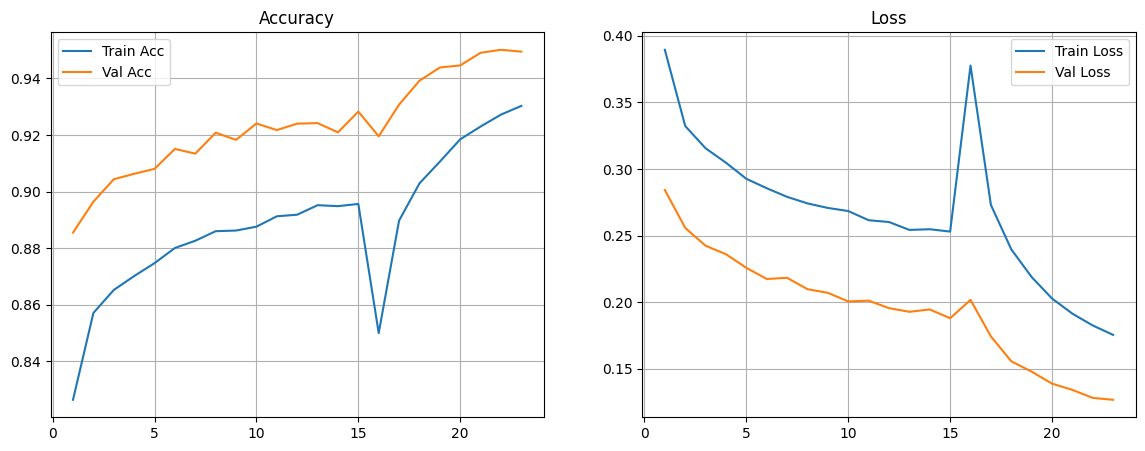

In [15]:
# 13. Training History Plots
def plot_history(h1, h2=None):
    acc = h1.history['accuracy'] + (h2.history['accuracy'] if h2 else [])
    val_acc = h1.history['val_accuracy'] + (h2.history['val_accuracy'] if h2 else [])
    loss = h1.history['loss'] + (h2.history['loss'] if h2 else [])
    val_loss = h1.history['val_loss'] + (h2.history['val_loss'] if h2 else [])

    epochs_range = range(1, len(acc)+1)

    plt.figure(figsize=(14,5))
    plt.subplot(1,2,1)
    plt.plot(epochs_range, acc, label='Train Acc')
    plt.plot(epochs_range, val_acc, label='Val Acc')
    plt.legend()
    plt.title('Accuracy')
    plt.grid(True)

    plt.subplot(1,2,2)
    plt.plot(epochs_range, loss, label='Train Loss')
    plt.plot(epochs_range, val_loss, label='Val Loss')
    plt.legend()
    plt.title('Loss')
    plt.grid(True)
    plt.show()

plot_history(history, history_ft)

In [16]:
# 14. PREDICTION CELL – Use on any picture
def predict_image(image_path, model=best_model, threshold=0.5, show=True):
    """
    Predict whether an image is REAL or FAKE (AI-generated / Deepfake).
    
    Returns:
        label (str), confidence (float), probability_of_fake (float)
    """
    img = load_img(image_path, target_size=IMG_SIZE)
    img_array = img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)

    prob_fake = model.predict(img_array, verbose=0)[0][0]
    
    if prob_fake >= threshold:
        label = "FAKE (AI-Generated / Deepfake)"
        confidence = prob_fake
    else:
        label = "REAL"
        confidence = 1 - prob_fake

    if show:
        plt.figure(figsize=(5,5))
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"{label}\nConfidence: {confidence*100:.1f}%\n(P(Fake)={prob_fake:.4f})")
        plt.show()

    return label, confidence, prob_fake


Sample Fake Image Prediction:


2026-10-18 04:09:13.826803: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 04:09:13.961108: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 04:09:14.697854: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-18 04:09:14.832049: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


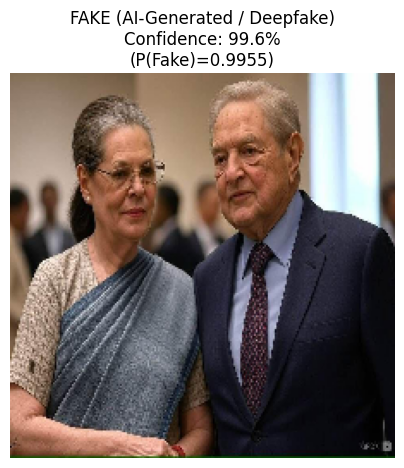

('FAKE (AI-Generated / Deepfake)',
 np.float32(0.9955212),
 np.float32(0.9955212))

In [17]:
# ---------- Examples ----------
# 1. Predict one of the sample fake images
sample_path = os.path.join(DF_SAMPLE_FAKE, "IMG-20250106-WA0009.jpg")
print("Sample Fake Image Prediction:")
predict_image(sample_path)

# 2. Predict any other image you upload to /kaggle/working or /kaggle/input
# Example:
# predict_image("/kaggle/working/my_test_image.jpg")

In [18]:
# 3. Batch prediction helper
def predict_folder(folder_path, model=best_model):
    results = []
    for fname in sorted(os.listdir(folder_path)):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
            path = os.path.join(folder_path, fname)
            label, conf, prob = predict_image(path, model=model, show=False)
            results.append((fname, label, conf, prob))
            print(f"{fname:40s} → {label:30s}  conf={conf*100:5.1f}%")
    return results

In [19]:
# Example: predict all sample fakes
print("\n=== All Sample Fake Images ===")
predict_folder(DF_SAMPLE_FAKE)

print("\n✅ Training finished. Best model saved at:")
print("/kaggle/working/models/best_deepfake_detector.keras")


=== All Sample Fake Images ===
IMG-20250106-WA0009.jpg                  → FAKE (AI-Generated / Deepfake)  conf= 99.6%
IMG-20250106-WA0010.jpg                  → FAKE (AI-Generated / Deepfake)  conf= 99.6%
IMG-20250106-WA0011.jpg                  → FAKE (AI-Generated / Deepfake)  conf= 99.6%
IMG-20250106-WA0012.jpg                  → FAKE (AI-Generated / Deepfake)  conf= 99.5%
IMG-20250106-WA0013.jpg                  → FAKE (AI-Generated / Deepfake)  conf= 99.7%

✅ Training finished. Best model saved at:
/kaggle/working/models/best_deepfake_detector.keras
